# Task 5: Numerical Univariate Analysis

**Objective:** Analyze numerical columns individually using histograms, boxplots, KDE plots, skewness, and kurtosis.

**Input:** `data/processed/womens_clothing_final.csv`  
**Output:** `reports/task_5_numerical_analysis.csv`

This notebook uses the Task 3 output rather than Task 4's scaled output, so the original treated feature distributions remain interpretable.

## 1. Import libraries

In [1]:
import logging
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")


## 2. Load dataset

In [2]:
current_path = Path.cwd()
PROJECT_ROOT = next(
    (p for p in [current_path, *current_path.parents]
     if (p / "data" / "processed" / "womens_clothing_final.csv").exists()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open the main Womens_Clothing_ML_Project folder in VS Code.")
INPUT_PATH = PROJECT_ROOT / "data" / "processed" / "womens_clothing_final.csv"
OUTPUT_PATH = PROJECT_ROOT / "data" / "processed"
REPORT_PATH = PROJECT_ROOT / "reports"
LOG_PATH = PROJECT_ROOT / "logs"
for folder in [OUTPUT_PATH, REPORT_PATH, LOG_PATH]:
    folder.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(INPUT_PATH)
print("Dataset shape:", df.shape)
display(df.head())

logging.basicConfig(
    filename=LOG_PATH / "task_5.log",
    level=logging.INFO,
    format="%(asctime)s - %(levelname)s - %(message)s",
    force=True
)


Dataset shape: (1539, 40)


,title,title_orig,price,retail_price,currency_buyer,units_sold,uses_ad_boosts,rating,rating_count,rating_five_count,...,merchant_name,merchant_info_subtitle,merchant_rating_count,merchant_rating,merchant_id,merchant_has_profile_picture,merchant_profile_picture,product_url,product_picture,product_id
0,2020 Summer Vintage Flamingo Print Pajamas Se...,2020 Summer Vintage Flamingo Print Pajamas Se...,16.00,14.0,EUR,100,False,3.76,54.0,26.0,...,zgrdejia,(568 notes),568.0,4.128521,595097d6a26f6e070cb878d1,False,NaN,https://www.wish.com/c/5e9ae51d43d6a96e303acdb0,https://contestimg.wish.com/api/webimage/5e9ae...,5e9ae51d43d6a96e303acdb0
1,SSHOUSE Summer Casual Sleeveless Soirée Party ...,Women's Casual Summer Sleeveless Sexy Mini Dress,8.00,22.0,EUR,12350,True,3.45,2143.5,1058.0,...,sarahouse,"83 % avis positifs (17,752 notes)",17752.0,3.899673,56458aa03a698c35c9050988,False,NaN,https://www.wish.com/c/58940d436a0d3d5da4e95a38,https://contestimg.wish.com/api/webimage/58940...,58940d436a0d3d5da4e95a38
2,2020 Nouvelle Arrivée Femmes Printemps et Été ...,2020 New Arrival Women Spring and Summer Beach...,8.00,43.0,EUR,100,False,3.57,14.0,5.0,...,hxt520,86 % avis positifs (295 notes),295.0,3.989831,5d464a1ffdf7bc44ee933c65,False,NaN,https://www.wish.com/c/5ea10e2c617580260d55310a,https://contestimg.wish.com/api/webimage/5ea10...,5ea10e2c617580260d55310a
3,Hot Summer Cool T-shirt pour les femmes Mode T...,Hot Summer Cool T Shirt for Women Fashion Tops...,8.00,8.0,EUR,5000,True,4.03,579.0,295.0,...,allenfan,"(23,832 notes)",23832.0,4.020435,58cfdefdacb37b556efdff7c,False,NaN,https://www.wish.com/c/5cedf17ad1d44c52c59e4aca,https://contestimg.wish.com/api/webimage/5cedf...,5cedf17ad1d44c52c59e4aca
4,Femmes Shorts d'été à lacets taille élastique ...,Women Summer Shorts Lace Up Elastic Waistband ...,2.72,3.0,EUR,100,True,3.10,20.0,6.0,...,happyhorses,"85 % avis positifs (14,482 notes)",14482.0,4.001588,5ab3b592c3911a095ad5dadb,False,NaN,https://www.wish.com/c/5ebf5819ebac372b070b0e70,https://contestimg.wish.com/api/webimage/5ebf5...,5ebf5819ebac372b070b0e70


## 3. Identify numerical columns

In [3]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
print("Numerical columns:", len(numeric_columns))
print(numeric_columns)
if not numeric_columns:
    raise ValueError("No numerical columns found.")


Numerical columns: 17
['price', 'retail_price', 'units_sold', 'rating', 'rating_count', 'rating_five_count', 'rating_four_count', 'rating_three_count', 'rating_two_count', 'rating_one_count', 'badges_count', 'product_variation_inventory', 'shipping_option_price', 'countries_shipped_to', 'inventory_total', 'merchant_rating_count', 'merchant_rating']


## 4. Calculate descriptive statistics, skewness, and kurtosis

In [4]:
def calculate_distribution_statistics(data, columns):
    results = []
    for col in columns:
        values = pd.to_numeric(data[col], errors="coerce")
        values = values.replace([np.inf, -np.inf], np.nan).dropna()
        if values.empty:
            continue

        skewness = values.skew()
        kurtosis = values.kurt()

        if abs(skewness) < 0.5:
            interpretation = "Approximately symmetric"
            suggestion = "No major skewness correction indicated"
        elif skewness >= 0.5:
            interpretation = "Positively skewed"
            suggestion = "Consider log1p or Power Transformation after checking values"
        else:
            interpretation = "Negatively skewed"
            suggestion = "Consider Power Transformation after checking values"

        results.append({
            "Feature": col,
            "Count": len(values),
            "Mean": values.mean(),
            "Median": values.median(),
            "Standard_Deviation": values.std(),
            "Minimum": values.min(),
            "Maximum": values.max(),
            "Skewness": skewness,
            "Kurtosis": kurtosis,
            "Skew_Interpretation": interpretation,
            "Suggested_Action": suggestion
        })
    return pd.DataFrame(results)

numerical_report = calculate_distribution_statistics(df, numeric_columns)
display(numerical_report)


,Feature,Count,Mean,Median,Standard_Deviation,Minimum,Maximum,Skewness,Kurtosis,Skew_Interpretation,Suggested_Action
0,price,1539,8.306087,8.00000,3.701039,1.000000,18.7625,0.476996,-0.056309,Approximately symmetric,No major skewness correction indicated
1,retail_price,1539,18.800845,10.00000,17.603829,1.000000,54.5000,1.176128,-0.185433,Positively skewed,Consider log1p or Power Transformation after c...
2,units_sold,1539,3152.889539,1000.00000,4215.210499,1.000000,12350.0000,1.165069,-0.205868,Positively skewed,Consider log1p or Power Transformation after c...
3,rating,1539,3.822840,3.85000,0.508619,1.000000,5.0000,-0.547370,2.892142,Negatively skewed,Consider Power Transformation after checking v...
4,rating_count,1539,570.270630,161.00000,742.296259,0.000000,2143.5000,1.213989,-0.017903,Positively skewed,Consider log1p or Power Transformation after c...
5,rating_five_count,1496,281.620989,84.00000,365.036715,0.000000,1058.0000,1.218060,-0.000380,Positively skewed,Consider log1p or Power Transformation after c...
6,rating_four_count,1496,113.167112,33.00000,146.145592,0.000000,420.0000,1.197143,-0.071310,Positively skewed,Consider log1p or Power Transformation after c...
7,rating_three_count,1496,86.221257,26.00000,112.290574,0.000000,329.0000,1.238112,0.058763,Positively skewed,Consider log1p or Power Transformation after c...
8,rating_two_count,1496,40.613636,12.00000,52.885278,0.000000,157.0000,1.245141,0.103049,Positively skewed,Consider log1p or Power Transformation after c...
9,rating_one_count,1496,62.861297,21.00000,79.995175,0.000000,236.5000,1.221889,0.043966,Positively skewed,Consider log1p or Power Transformation after c...


## 5. Custom histogram function

In [5]:
def plot_histogram(data, column):
    values = pd.to_numeric(data[column], errors="coerce").dropna()
    if values.empty:
        print(f"No data available for {column}")
        return
    plt.figure(figsize=(8, 4))
    sns.histplot(values, bins=30, kde=False)
    plt.title(f"Histogram of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


## 6. Custom boxplot function

In [6]:
def plot_boxplot(data, column):
    values = pd.to_numeric(data[column], errors="coerce").dropna()
    if values.empty:
        print(f"No data available for {column}")
        return
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=values)
    plt.title(f"Boxplot of {column}")
    plt.xlabel(column)
    plt.tight_layout()
    plt.show()


## 7. Custom KDE function

In [7]:
def plot_kde(data, column):
    values = pd.to_numeric(data[column], errors="coerce").dropna()
    if values.empty or values.nunique() < 2:
        print(f"KDE cannot be generated for {column}")
        return
    plt.figure(figsize=(8, 4))
    sns.kdeplot(x=values, fill=True)
    plt.title(f"KDE Plot of {column}")
    plt.xlabel(column)
    plt.ylabel("Density")
    plt.tight_layout()
    plt.show()


## 8. Generate visualizations for numerical features

\n============================================================
Feature: price


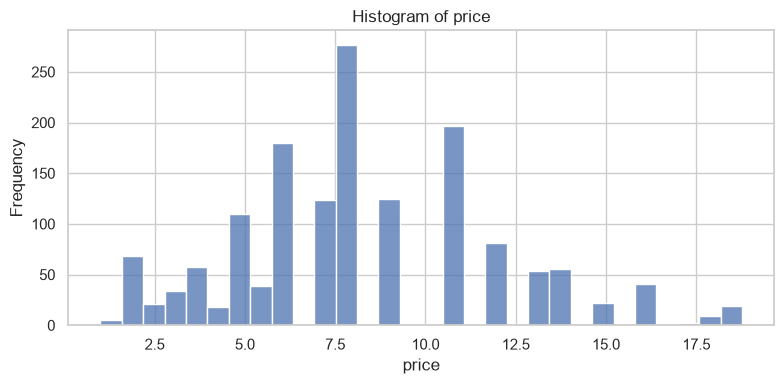

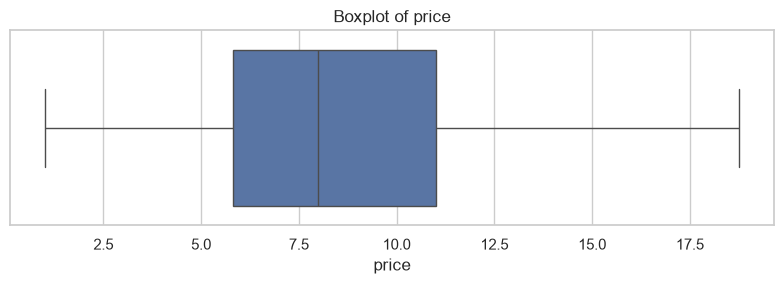

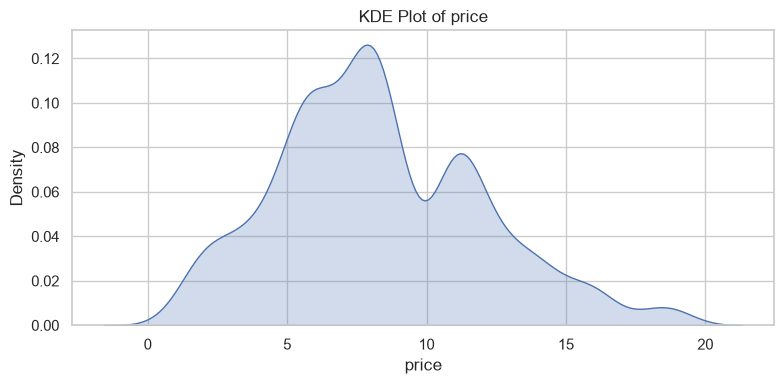

\n============================================================
Feature: retail_price


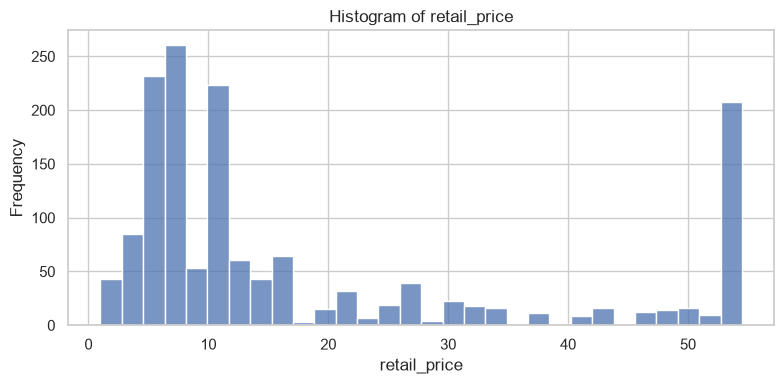

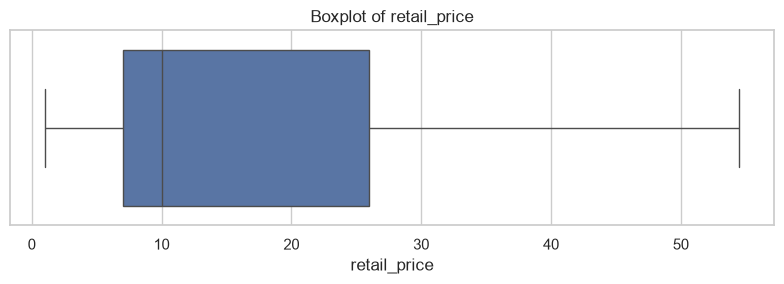

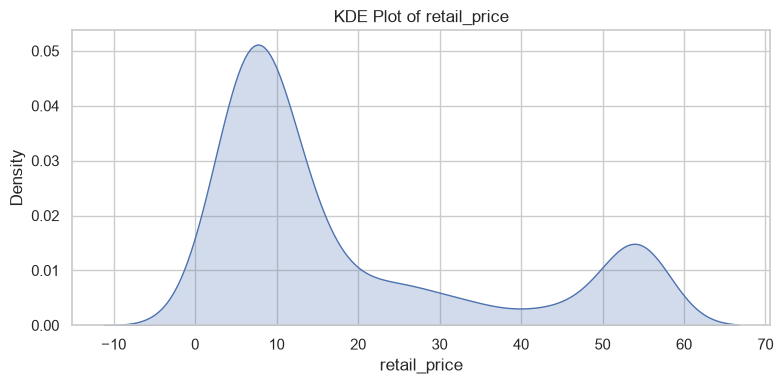

\n============================================================
Feature: units_sold


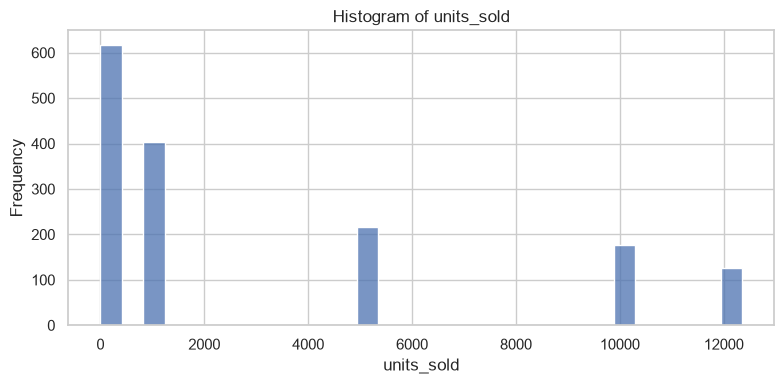

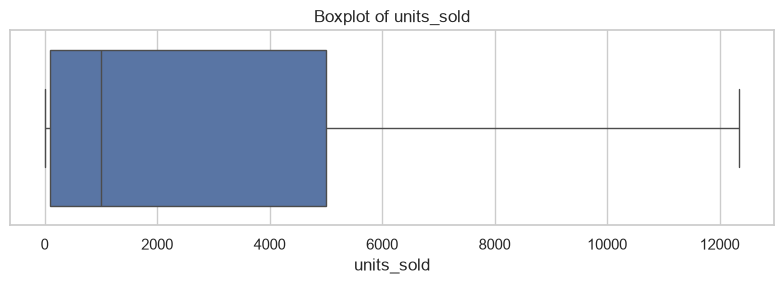

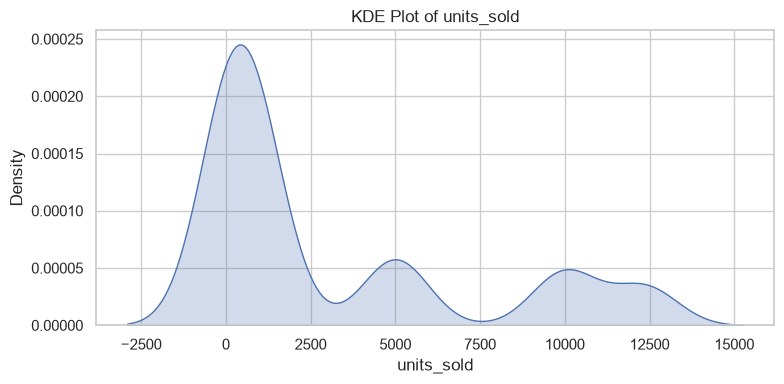

\n============================================================
Feature: rating


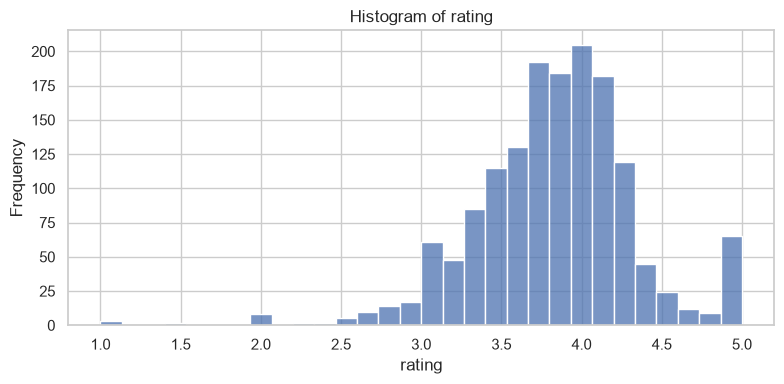

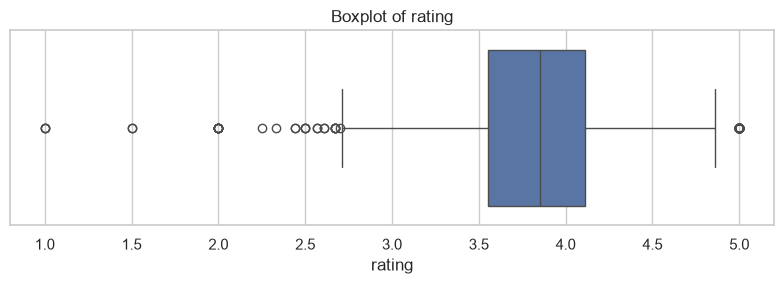

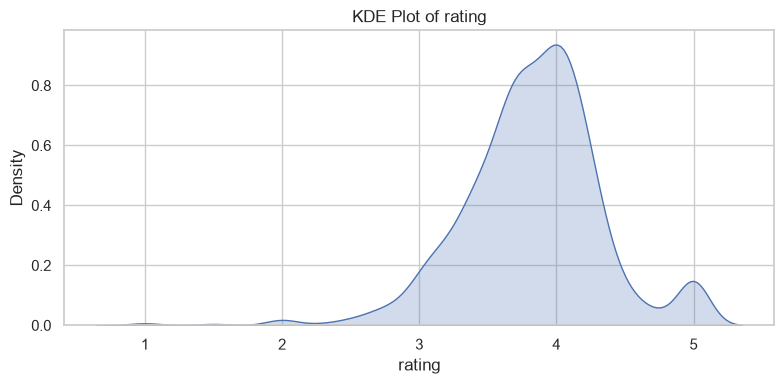

\n============================================================
Feature: rating_count


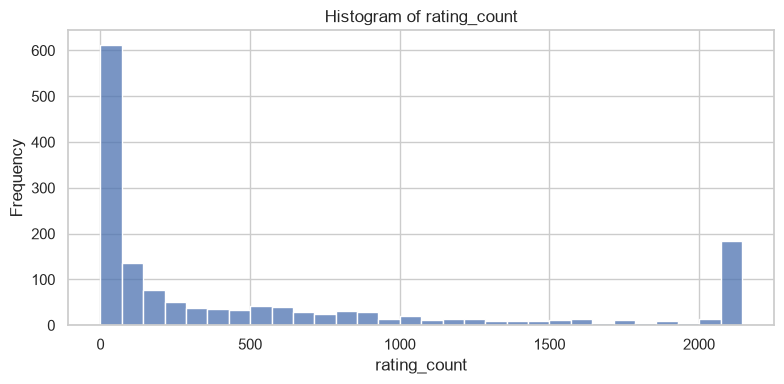

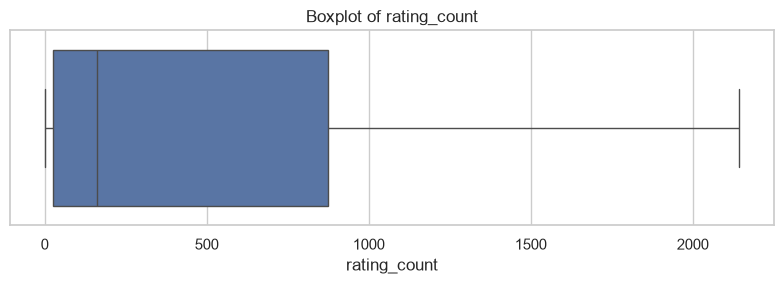

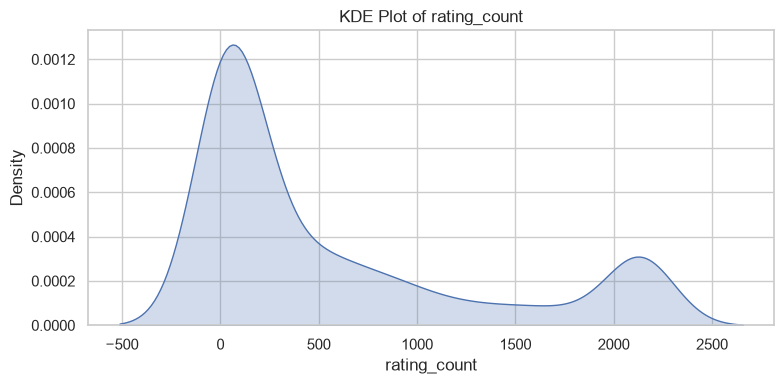

\n============================================================
Feature: rating_five_count


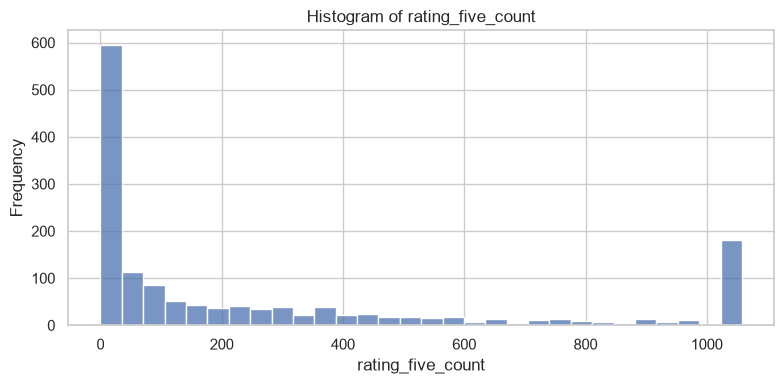

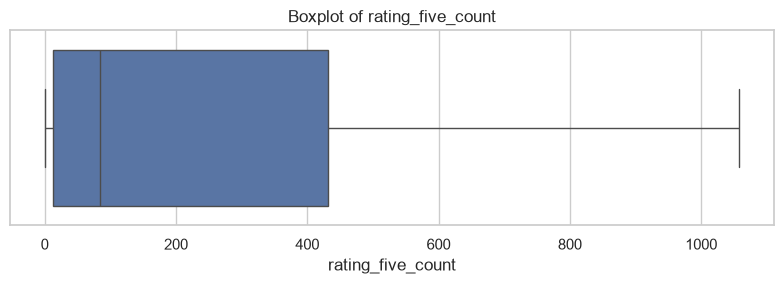

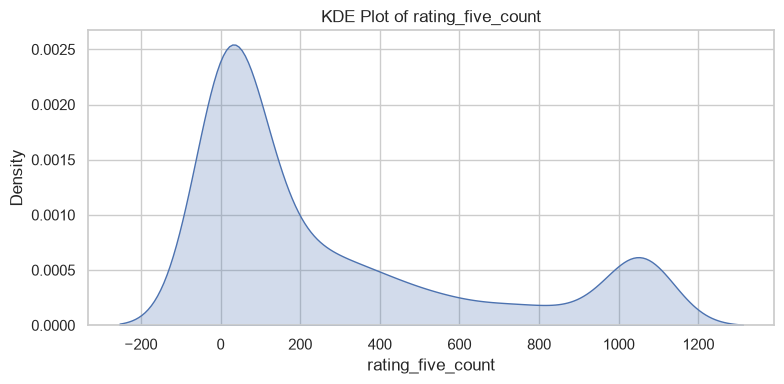

\n============================================================
Feature: rating_four_count


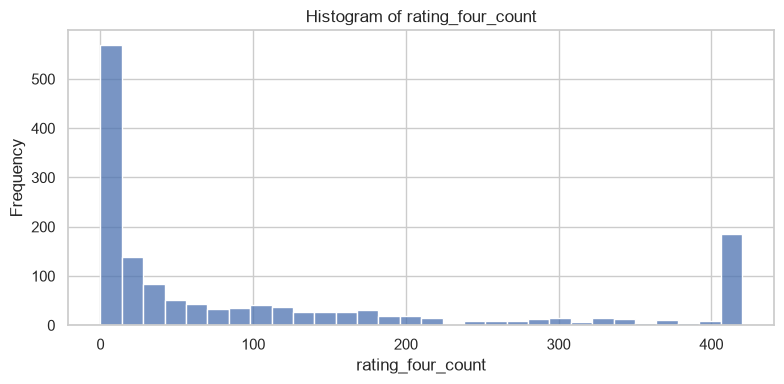

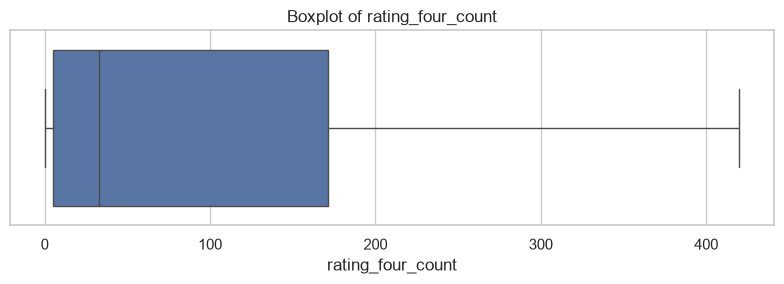

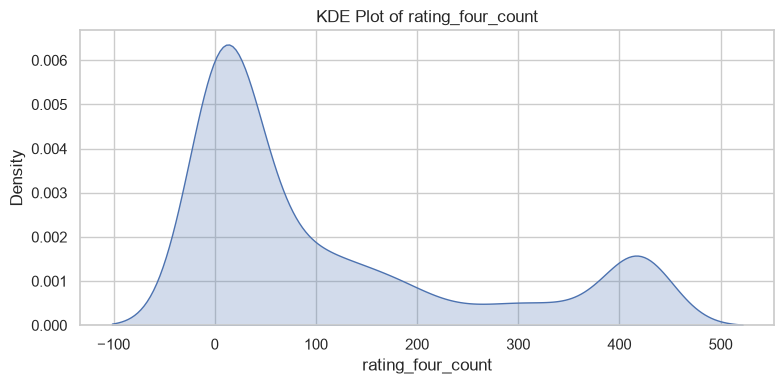

\n============================================================
Feature: rating_three_count


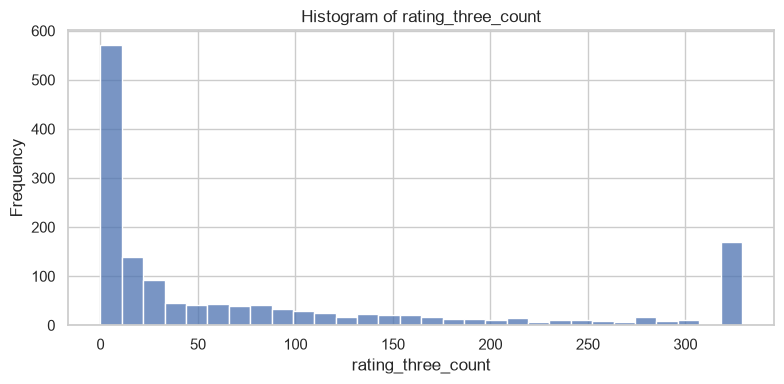

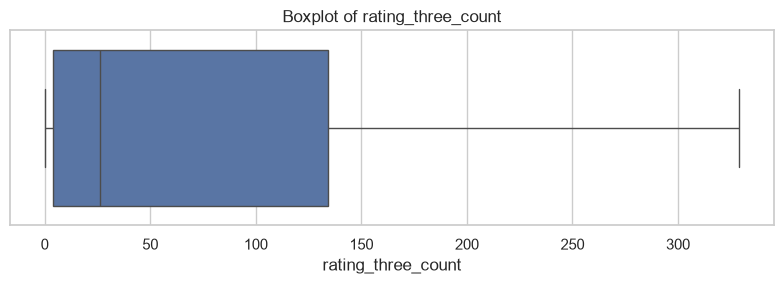

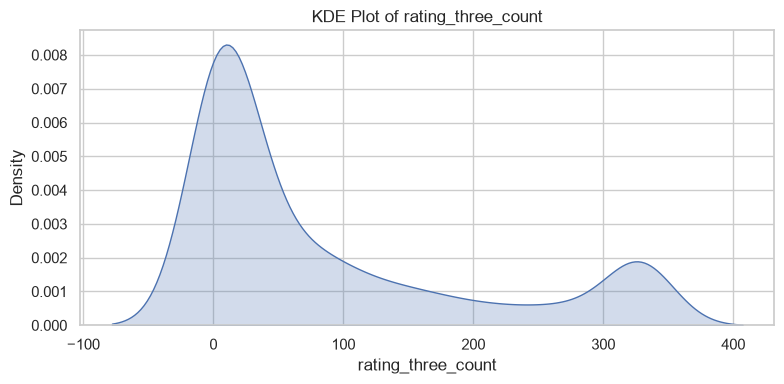

\n============================================================
Feature: rating_two_count


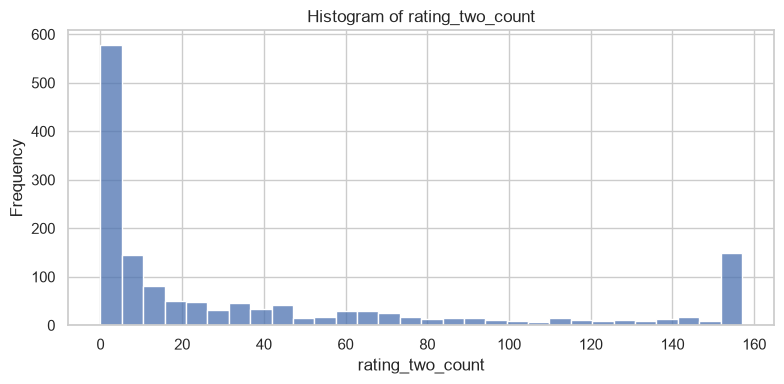

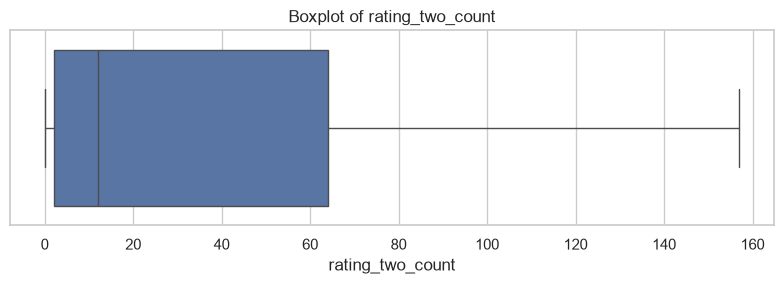

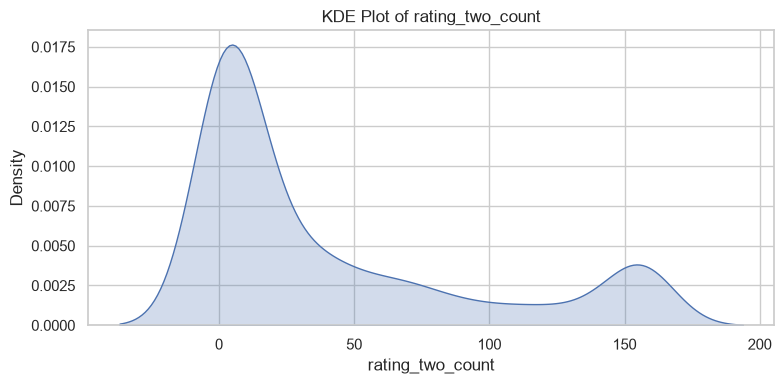

\n============================================================
Feature: rating_one_count


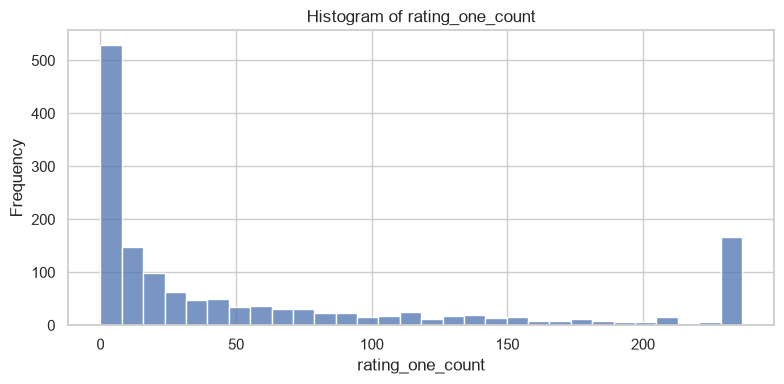

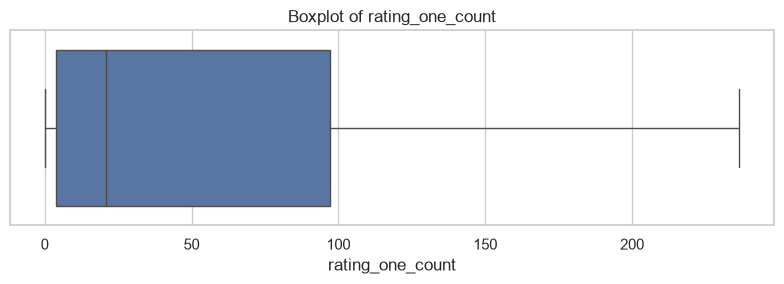

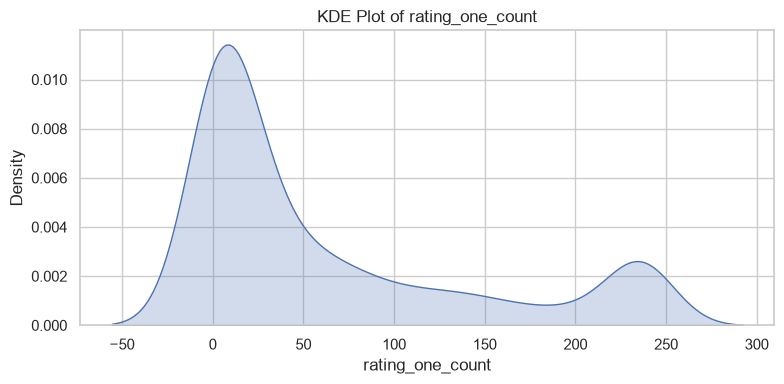

\n============================================================
Feature: badges_count


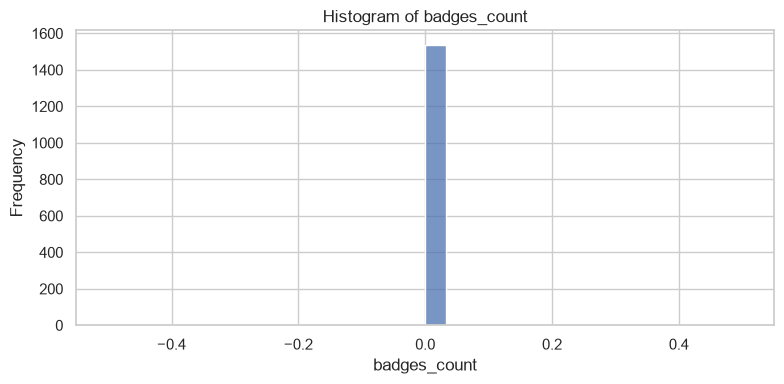

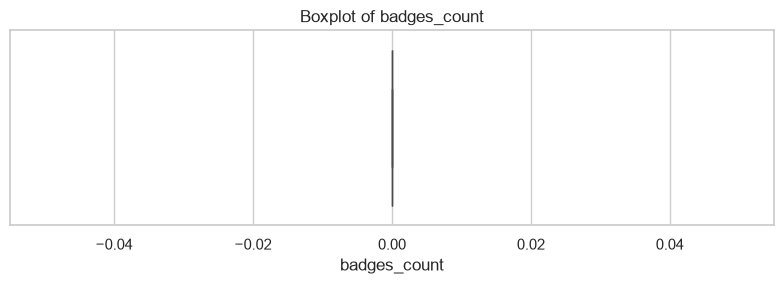

KDE cannot be generated for badges_count
\n============================================================
Feature: product_variation_inventory


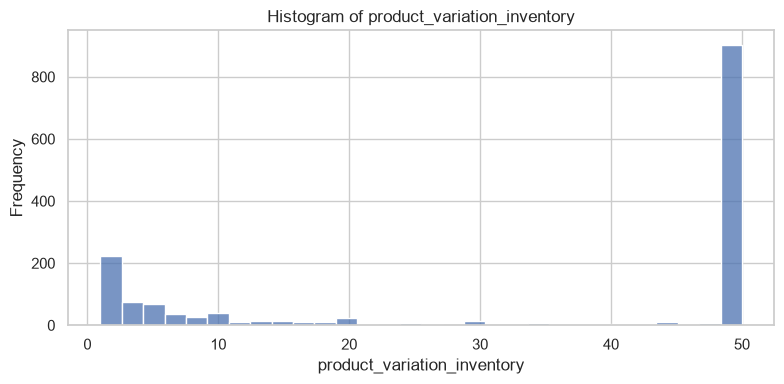

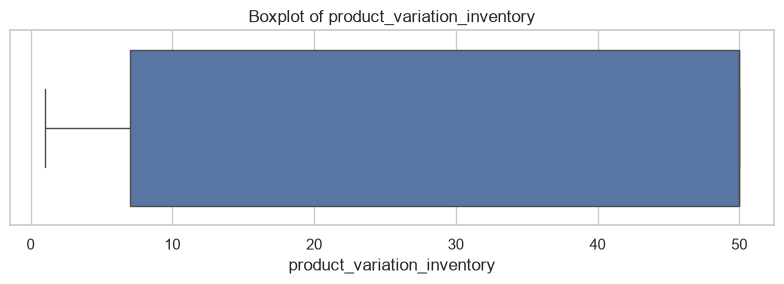

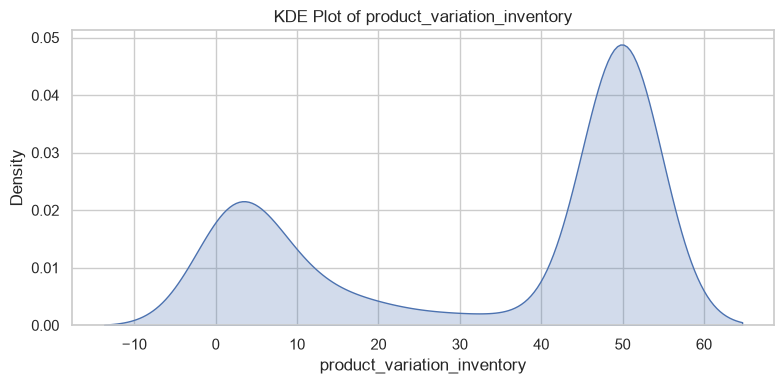

\n============================================================
Feature: shipping_option_price


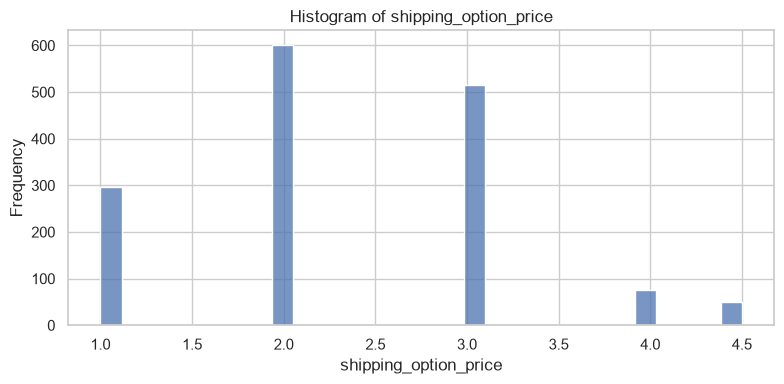

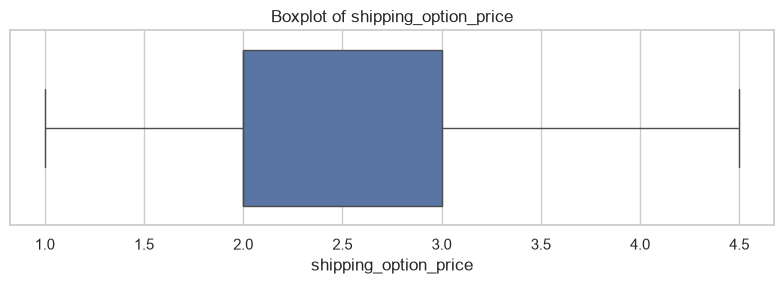

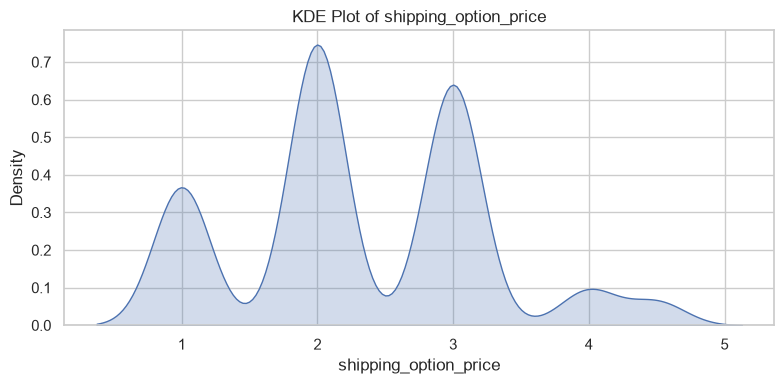

\n============================================================
Feature: countries_shipped_to


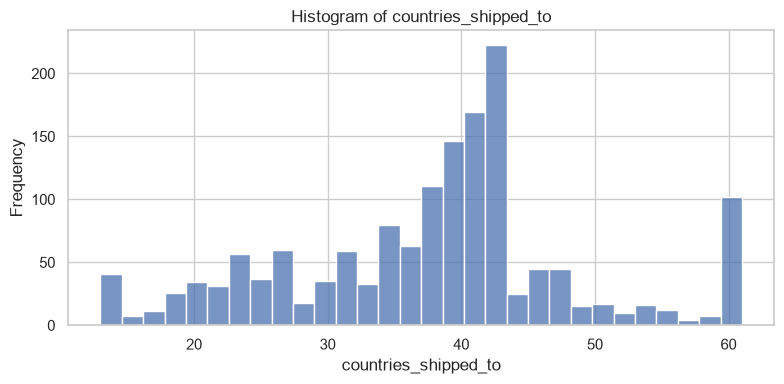

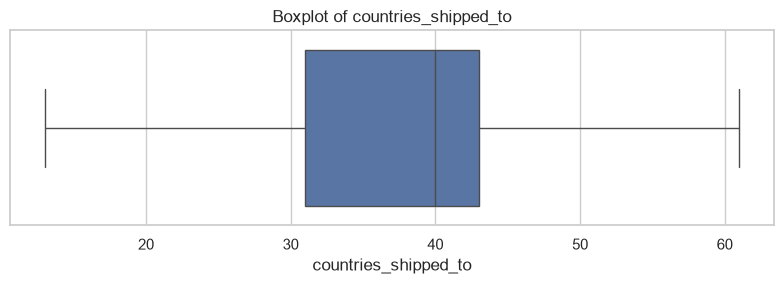

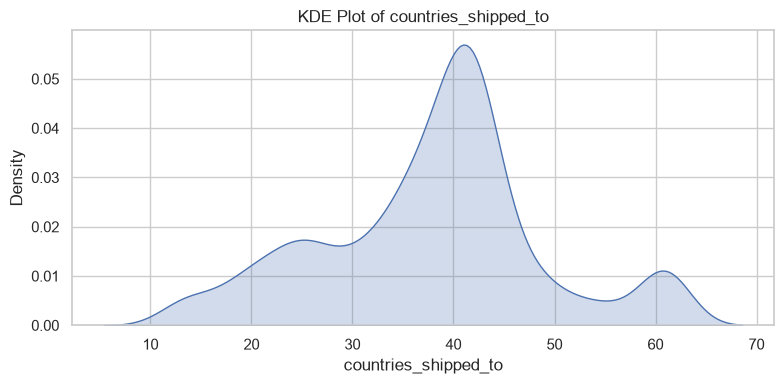

\n============================================================
Feature: inventory_total


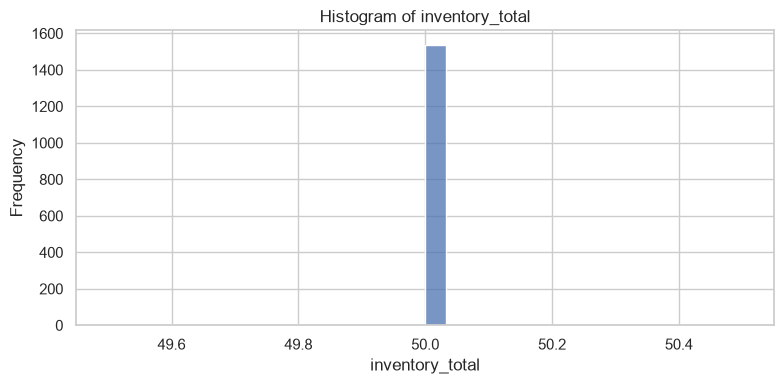

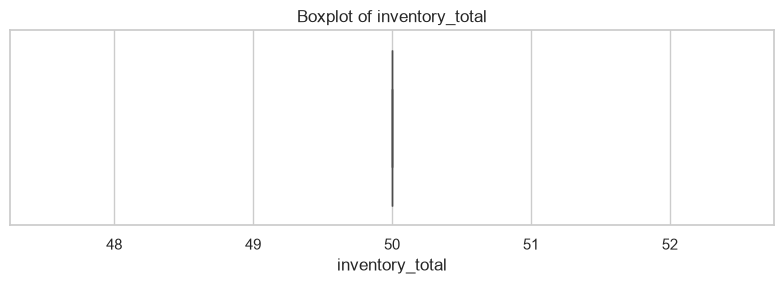

KDE cannot be generated for inventory_total
\n============================================================
Feature: merchant_rating_count


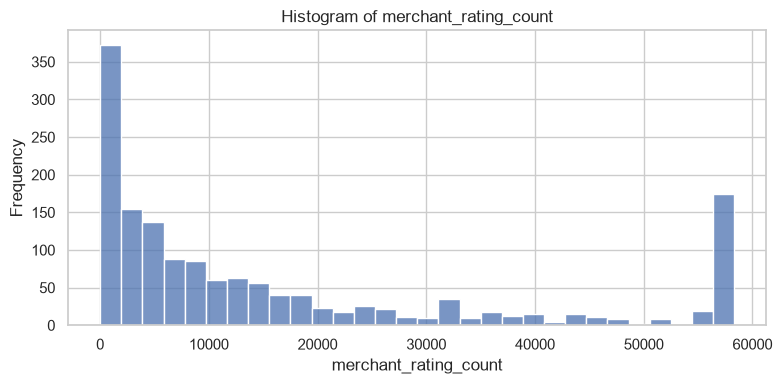

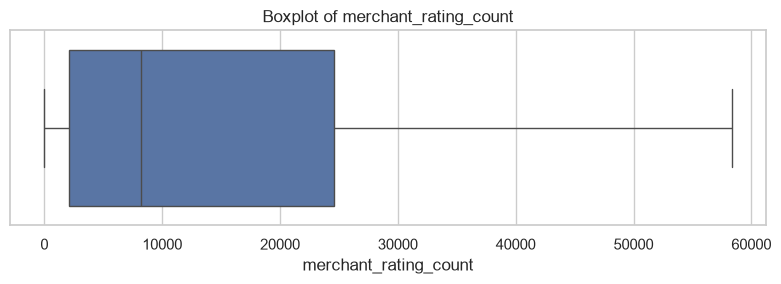

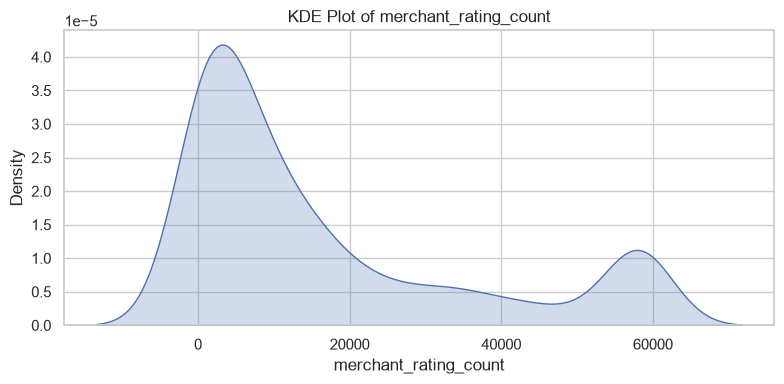

\n============================================================
Feature: merchant_rating


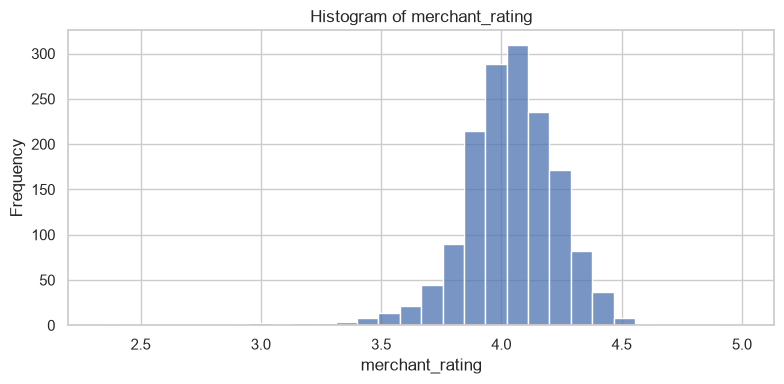

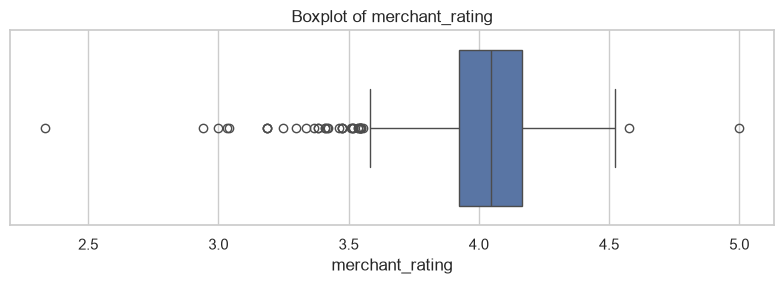

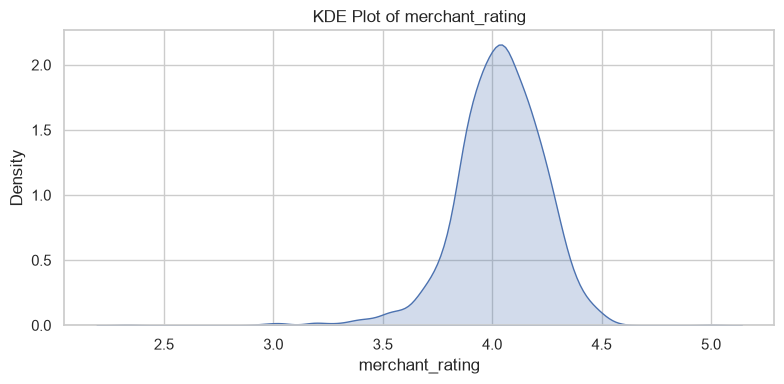

In [8]:
for col in numeric_columns:
    print("\\n" + "=" * 60)
    print("Feature:", col)
    plot_histogram(df, col)
    plot_boxplot(df, col)
    plot_kde(df, col)


## 9. Identify highly skewed features

In [9]:
skewed_features = numerical_report[
    numerical_report["Skewness"].abs() > 1
].sort_values(
    by="Skewness",
    key=lambda values: values.abs(),
    ascending=False
)
print("Highly skewed numerical features:")
display(skewed_features[["Feature", "Skewness", "Kurtosis", "Suggested_Action"]])


Highly skewed numerical features:


,Feature,Skewness,Kurtosis,Suggested_Action
8,rating_two_count,1.245141,0.103049,Consider log1p or Power Transformation after c...
7,rating_three_count,1.238112,0.058763,Consider log1p or Power Transformation after c...
9,rating_one_count,1.221889,0.043966,Consider log1p or Power Transformation after c...
5,rating_five_count,1.218060,-0.000380,Consider log1p or Power Transformation after c...
4,rating_count,1.213989,-0.017903,Consider log1p or Power Transformation after c...
15,merchant_rating_count,1.199373,0.041110,Consider log1p or Power Transformation after c...
6,rating_four_count,1.197143,-0.071310,Consider log1p or Power Transformation after c...
1,retail_price,1.176128,-0.185433,Consider log1p or Power Transformation after c...
2,units_sold,1.165069,-0.205868,Consider log1p or Power Transformation after c...
16,merchant_rating,-1.045650,5.519846,Consider Power Transformation after checking v...


## 10. Visualize skewness and kurtosis

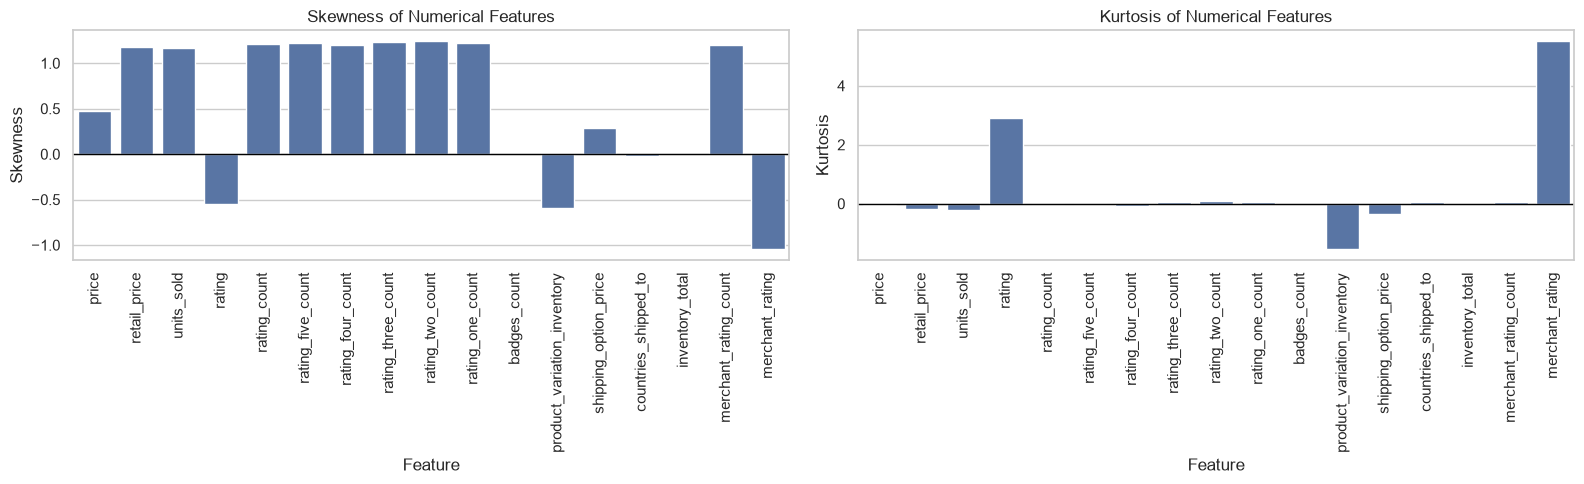

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=numerical_report, x="Feature", y="Skewness", ax=axes[0])
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_title("Skewness of Numerical Features")
axes[0].tick_params(axis="x", rotation=90)

sns.barplot(data=numerical_report, x="Feature", y="Kurtosis", ax=axes[1])
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Kurtosis of Numerical Features")
axes[1].tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()


## 11. Save analysis report

In [11]:
REPORT_FILE = REPORT_PATH / "task_5_numerical_analysis.csv"
numerical_report.to_csv(REPORT_FILE, index=False)
logging.info("Numerical univariate analysis completed.")
logging.info("Analyzed %d numerical columns.", len(numeric_columns))
logging.info("Report saved to %s", REPORT_FILE)
print("Report saved:", REPORT_FILE)


Report saved: d:\OneDrive\Desktop\Brainybeams\Womens_Clothing_ML_Project\reports\task_5_numerical_analysis.csv


## 12. Final summary

In [12]:
print("TASK 5 COMPLETED")
print("Numerical columns analyzed:", len(numeric_columns))
print("Highly skewed columns:", len(skewed_features))
print("Report:", REPORT_FILE)


TASK 5 COMPLETED
Numerical columns analyzed: 17
Highly skewed columns: 10
Report: d:\OneDrive\Desktop\Brainybeams\Womens_Clothing_ML_Project\reports\task_5_numerical_analysis.csv


## Interpretation

- Skewness near zero suggests an approximately symmetric distribution.
- Positive skewness indicates a longer right tail.
- Negative skewness indicates a longer left tail.
- Pandas reports excess kurtosis; values near zero are close to the normal-distribution convention.

Suggested transformations are diagnostic recommendations only. Check each feature's meaning and valid range before transforming it.